# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

`%pip install numpy scipy matplotlib` để cài thư viện


Python 3.12.14 NumPy 2.5.4 SciPy 1.18.1


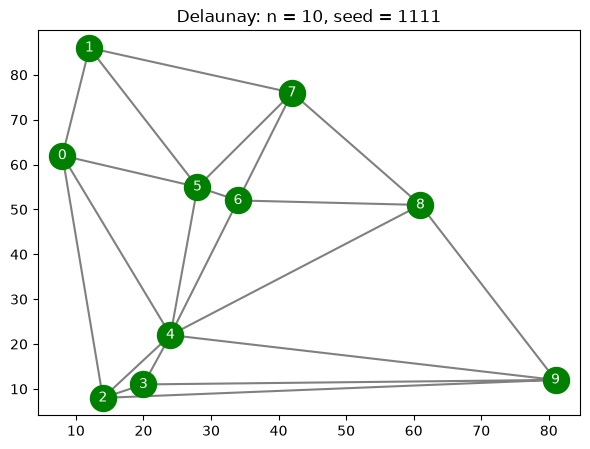

In [1]:
import sys, platform, time, random
import numpy as np
import scipy
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
from IPython.display import display, Markdown
print("Python", platform.python_version(), "NumPy", np.__version__, "SciPy", scipy.__version__)
np.random.seed(1111)
n = 10
points = np.random.randint(100, size=(n, 2))
points = points[np.argsort(points[:, 0])]
tri = Delaunay(points)
plt.figure(figsize=(7, 5))
plt.triplot(points[:,0], points[:,1], tri.simplices, color='gray')
plt.scatter(*points.T, s=350, color='green')
for i,p in enumerate(points): plt.annotate(str(i), p, ha='center', va='center', color='white')
plt.title('Delaunay: n = 10, seed = 1111'); plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

**Mô hình:** $X=\{0,\ldots,n-1\}$; $D_i$ là 3 hoặc 4 màu; $C_{ij}:x_i\ne x_j$ với mỗi cạnh. Chỉ lưu $i<j$ vì cạnh vô hướng có ràng buộc đối xứng, tránh đếm hai lần. Mỗi biến có bản sao miền riêng để Forward Checking không làm đổi miền của biến khác.


In [3]:
variables = [str(i) for i in range(n)]
domain = ['red', 'blue', 'green', 'orange']
domains = {v: list(domain) for v in variables}
constraints = [(str(i), str(j)) for i in range(n) for j in neighbors[i] if i < j]
csp = {'variables': variables, 'domains': domains, 'constraints': constraints}
display(csp)

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': [('0', '1'),
  ('0', '2'),
  ('0', '4'),
  ('0', '5'),
  ('1', '5'),
  ('1', '7'),
  ('2', '3'),
  ('2', '4'),
  ('2', '9'),
  ('3', '4'),
  ('3', '9'),
  ('4', '5'),
  ('4', '6'),
  ('4', '8'),
  ('4', '9'),
  ('5', '6'),
  ('5', '7'),
  ('6', '7'),
  ('6', '8'),
  ('7', '8'),
  ('8', '9')]}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [4]:
def complete(assignment, csp):
    return all(v in assignment for v in csp['variables'])
print('Phép gán rỗng đầy đủ:', complete({}, csp))
print('Gán hết màu đỏ đầy đủ:', complete(dict.fromkeys(variables, 'red'), csp))

Phép gán rỗng đầy đủ: False
Gán hết màu đỏ đầy đủ: True


In [5]:
def consistent(assignment, csp):
    if any(v not in csp['domains'] or x not in csp['domains'][v] for v,x in assignment.items()):
        return False
    return all(a not in assignment or b not in assignment or assignment[a] != assignment[b]
               for a,b in csp['constraints'])

a,b = constraints[0]
cases = [('Rỗng', {}, False, True),
         ('Một phần hợp lệ', {a:'red'}, False, True),
         ('Hai đỉnh kề cùng màu', {a:'red',b:'red'}, False, False),
         ('Đầy đủ nhưng sai', dict.fromkeys(variables,'red'), True, False),
         ('Màu ngoài miền', {a:'purple'}, False, False)]
for label, assignment, ec, es in cases:
    assert (complete(assignment,csp),consistent(assignment,csp)) == (ec,es)
    print(label, ': complete =',ec, ', consistent =',es)
print('Tất cả kiểm thử đạt.')

Rỗng : complete = False , consistent = True
Một phần hợp lệ : complete = False , consistent = True
Hai đỉnh kề cùng màu : complete = False , consistent = False
Đầy đủ nhưng sai : complete = True , consistent = False
Màu ngoài miền : complete = False , consistent = False
Tất cả kiểm thử đạt.


## Implement Simple Backtracking Search

`complete()` chỉ xét đủ biến; `consistent()` xét miền và ràng buộc trên các biến đã gán. Nghiệm cần đồng thời đầy đủ và nhất quán; phép gán một phần nhất quán chưa chắc mở rộng được thành nghiệm.

In [6]:
def adjacency(csp):
    adj = {v:set() for v in csp['variables']}
    for a,b in csp['constraints']: adj[a].add(b); adj[b].add(a)
    return adj

def legal_values(v, assignment, csp, adj, remaining):
    return [x for x in remaining[v] if all(assignment.get(u) != x for u in adj[v])]

def select_unassigned_var(assignment, csp, remaining=None, use_mrv=True):
    pending = [v for v in csp['variables'] if v not in assignment]
    if not pending: return None
    if not use_mrv: return pending[0]
    remaining = csp['domains'] if remaining is None else remaining
    adj = adjacency(csp)
    return min(pending, key=lambda v: len(legal_values(v,assignment,csp,adj,remaining)))

def order_domain(assignment, var, csp, remaining, adj, use_lcv=True):
    values = list(remaining[var])
    if use_lcv:
        values.sort(key=lambda x: sum(x in legal_values(u,assignment,csp,adj,remaining)
                        for u in adj[var] if u not in assignment))
    return values

In [7]:
COUNT = 0
VERBOSE = False
def backtrack_search(csp, use_mrv=True, use_lcv=True, forward_check=True, max_nodes=None):
    """COUNT = số lần gọi nút đệ quy, kể cả gốc; attempts = số giá trị thử gán."""
    global COUNT, LAST_STATS
    COUNT = 0
    stats = {'attempts':0, 'status':'unsat'}
    adj = adjacency(csp)
    remaining = {v:list(d) for v,d in csp['domains'].items()}
    def visit(assignment):
        global COUNT
        if max_nodes is not None and COUNT >= max_nodes: raise RuntimeError('node_limit')
        COUNT += 1
        if complete(assignment,csp): return assignment.copy()
        var = select_unassigned_var(assignment,csp,remaining,use_mrv)
        for val in order_domain(assignment,var,csp,remaining,adj,use_lcv):
            stats['attempts'] += 1
            if any(assignment.get(u) == val for u in adj[var]): continue
            assignment[var] = val
            removed = []
            failed = False
            if forward_check:
                for u in adj[var]:
                    if u not in assignment and val in remaining[u]:
                        index = remaining[u].index(val)
                        remaining[u].pop(index); removed.append((u,index,val))
                        if not remaining[u]: failed = True
            result = None if failed else visit(assignment)
            # Hoàn tác cả nội dung lẫn thứ tự miền trước khi thử nhánh kế tiếp.
            for u,index,x in reversed(removed): remaining[u].insert(index,x)
            del assignment[var]
            if result is not None: return result
        return None
    t0 = time.perf_counter()
    try:
        result = visit({})
        stats['status'] = 'solved' if result is not None else 'unsat'
    except RuntimeError as e:
        if str(e) != 'node_limit': raise
        result = None; stats['status'] = 'limit'
    stats.update(nodes=COUNT, seconds=time.perf_counter()-t0)
    LAST_STATS = stats
    return result

## Run Backtracking Search on the Random Problem

In [8]:
res = backtrack_search(csp)
print(LAST_STATS)
assert res is not None and complete(res,csp) and consistent(res,csp)
display(res)

{'attempts': 10, 'status': 'solved', 'nodes': 11, 'seconds': 0.0012843000004068017}


{'0': 'red',
 '1': 'blue',
 '5': 'green',
 '4': 'blue',
 '2': 'green',
 '3': 'red',
 '9': 'orange',
 '6': 'orange',
 '7': 'red',
 '8': 'green'}

Plot the resulting coloring

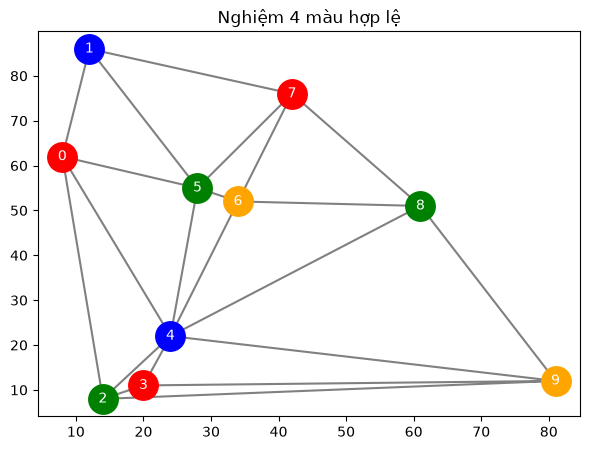

In [9]:
def draw_coloring(points, tri, assignment):
    plt.figure(figsize=(7,5))
    plt.triplot(points[:,0],points[:,1],tri.simplices,color='gray')
    for i,p in enumerate(points):
        plt.scatter(*p,s=450,color=assignment[str(i)] if assignment else 'gray')
        plt.annotate(str(i),p,ha='center',va='center',color='white')
    plt.title('Nghiệm 4 màu hợp lệ' if assignment else 'Chưa tìm được nghiệm')
    plt.show()
draw_coloring(points,tri,res)

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

MRV đếm giá trị **còn hợp lệ**, kể cả khi không dùng Forward Checking. LCV ưu tiên màu loại ít lựa chọn của các láng giềng chưa gán nhất. Forward Checking loại màu vừa gán ở các láng giềng và hoàn tác miền khi quay lui.

Min-Conflicts khởi tạo đầy đủ, chọn ngẫu nhiên một biến đang xung đột rồi chọn màu có ít xung đột nhất (phá hòa ngẫu nhiên). Cho phép bước ngang để thoát plateau. Vì vẫn xét màu hiện tại trong các ứng viên, màu tốt nhất không thể tăng số xung đột: bộ đếm bước tăng h bằng 0. Restart thay khởi tạo để thoát kẹt; bảng ghi số restart thực tế. Hết ngân sách tìm kiếm cục bộ không chứng minh vô nghiệm.

In [10]:
def edge_conflicts(assignment, csp):
    return sum(assignment[a] == assignment[b] for a,b in csp['constraints'])

def min_conflicts(csp, seed=0, max_steps=1000, max_restarts=5):
    rng = random.Random(seed); adj = adjacency(csp)
    best = None; best_h = float('inf'); steps = uphill = 0
    t0 = time.perf_counter()
    for restart in range(max_restarts+1):
        state = {v:rng.choice(csp['domains'][v]) for v in csp['variables']}
        h = edge_conflicts(state,csp)
        if h < best_h: best,best_h = state.copy(),h
        if h == 0: break
        for _ in range(max_steps):
            bad = [v for v in state if any(state[v] == state[u] for u in adj[v])]
            v = rng.choice(bad)
            scores = [(sum(x == state[u] for u in adj[v]), x) for x in csp['domains'][v]]
            lowest = min(s for s,x in scores)
            old_local = sum(state[v] == state[u] for u in adj[v])
            state[v] = rng.choice([x for s,x in scores if s == lowest])
            new_h = h + lowest - old_local
            uphill += int(new_h > h); h = new_h; steps += 1
            if h < best_h: best,best_h = state.copy(),h
            if h == 0: break
        if h == 0: break
    return best, dict(status='solved' if best_h == 0 else 'limit', conflicts=best_h,
                     steps=steps, uphill=uphill, restarts=restart, seconds=time.perf_counter()-t0)

def make_graph(n,k,seed):
    rng = np.random.default_rng(seed)
    p = rng.random((n,2)); t = Delaunay(p)
    ind,idx = t.vertex_neighbor_vertices
    edges = [(str(i),str(j)) for i in range(n) for j in idx[ind[i]:ind[i+1]] if i<j]
    return {'variables':[str(i) for i in range(n)],
            'domains':{str(i):domain[:k].copy() for i in range(n)}, 'constraints':edges}

# Tam giác cần 3 màu; K4 cần 4 màu. Kiểm tra vô nghiệm và hoàn tác miền.
tiny = {'variables':['a','b','c'], 'domains':{v:['red','blue'] for v in 'abc'},
        'constraints':[('a','b'),('b','c'),('a','c')]}
import copy
before = copy.deepcopy(tiny)
assert backtrack_search(tiny) is None and LAST_STATS['status'] == 'unsat'
assert tiny == before
for v in tiny['variables']: tiny['domains'][v].append('green')
assert consistent(backtrack_search(tiny),tiny)
print('Kiểm thử tam giác và bảo toàn miền: đạt.')

Kiểm thử tam giác và bảo toàn miền: đạt.


### Thí nghiệm trên cùng dữ liệu
Mỗi cặp (n, số màu) dùng 10 seed 0–9, n = 10, 20, 40. Ba biến thể Backtracking có giới hạn 100.000 nút/lượt; Min-Conflicts tối đa 1.000 bước mỗi lần và 5 restart. Mỗi thuật toán nhận cùng đồ thị. Trung bình lấy trên **toàn bộ 10 lượt**, kể cả thất bại; thời gian bao gồm tìm kiếm, không gồm sinh đồ thị/vẽ. `unsat` chỉ ghi khi Backtracking đã duyệt hết; `limit` chỉ là hết ngân sách. COUNT không phải số phép gán thử.

In [11]:
graph_records = []
variants = [('Backtracking',False,False,False),('MRV + LCV',True,True,False),('MRV + LCV + FC',True,True,True)]
for size in [10,20,40]:
    for k in [3,4]:
        for seed in range(10):
            problem = make_graph(size,k,seed)
            for name,mrv,lcv,fc in variants:
                ans = backtrack_search(problem,mrv,lcv,fc,max_nodes=100000)
                s = LAST_STATS.copy()
                if ans is not None: assert complete(ans,problem) and consistent(ans,problem)
                graph_records.append(dict(n=size,k=k,seed=seed,algorithm=name,edges=len(problem['constraints']),**s))
            ans,s = min_conflicts(problem,seed)
            if s['status'] == 'solved': assert consistent(ans,problem)
            graph_records.append(dict(n=size,k=k,seed=seed,algorithm='Min-Conflicts',edges=len(problem['constraints']),**s))

def avg(rows,key): return float(np.mean([r[key] for r in rows]))
lines = ['| n | Màu | Thuật toán | Cạnh TB | Thành công % | UNSAT / limit | COUNT TB | Gán thử / bước TB | Tăng h TB | Restart TB | Giây TB |',
         '|---|---|---|---|---|---|---|---|---|---|---|']
for size in [10,20,40]:
    for k in [3,4]:
        for name in [x[0] for x in variants]+['Min-Conflicts']:
            rows=[r for r in graph_records if (r['n'],r['k'],r['algorithm'])==(size,k,name)]
            local=name=='Min-Conflicts'
            lines.append(f"|{size}|{k}|{name}|{avg(rows,'edges'):.1f}|{100*np.mean([r['status']=='solved' for r in rows]):.0f}|{sum(r['status']=='unsat' for r in rows)} / {sum(r['status']=='limit' for r in rows)}|{'—' if local else round(avg(rows,'nodes'),1)}|{avg(rows,'steps' if local else 'attempts'):.1f}|{round(avg(rows,'uphill'),1) if local else '—'}|{round(avg(rows,'restarts'),1) if local else '—'}|{avg(rows,'seconds'):.6f}|")
display(Markdown('\n'.join(lines)))

| n | Màu | Thuật toán | Cạnh TB | Thành công % | UNSAT / limit | COUNT TB | Gán thử / bước TB | Tăng h TB | Restart TB | Giây TB |
|---|---|---|---|---|---|---|---|---|---|---|
|10|3|Backtracking|21.2|10|9 / 0|156.5|468.1|—|—|0.002271|
|10|3|MRV + LCV|21.2|10|9 / 0|32.9|97.3|—|—|0.004369|
|10|3|MRV + LCV + FC|21.2|10|9 / 0|27.5|31.9|—|—|0.002190|
|10|3|Min-Conflicts|21.2|10|0 / 9|—|5401.9|0.0|4.5|0.159937|
|10|4|Backtracking|21.2|100|0 / 0|11.8|26.1|—|—|0.000157|
|10|4|MRV + LCV|21.2|100|0 / 0|11.0|23.9|—|—|0.001303|
|10|4|MRV + LCV + FC|21.2|100|0 / 0|11.0|10.0|—|—|0.000763|
|10|4|Min-Conflicts|21.2|100|0 / 0|—|7.3|0.0|0.0|0.000233|
|20|3|Backtracking|49.1|0|10 / 0|2295.4|6886.2|—|—|0.025776|
|20|3|MRV + LCV|49.1|0|10 / 0|32.8|98.4|—|—|0.005332|
|20|3|MRV + LCV + FC|49.1|0|10 / 0|26.8|31.8|—|—|0.003048|
|20|3|Min-Conflicts|49.1|0|0 / 10|—|6000.0|0.0|5.0|0.212558|
|20|4|Backtracking|49.1|100|0 / 0|125.3|465.6|—|—|0.001988|
|20|4|MRV + LCV|49.1|100|0 / 0|21.0|52.9|—|—|0.004221|
|20|4|MRV + LCV + FC|49.1|100|0 / 0|21.0|20.0|—|—|0.002746|
|20|4|Min-Conflicts|49.1|100|0 / 0|—|46.1|0.0|0.0|0.002222|
|40|3|Backtracking|108.0|0|4 / 6|73312.0|219924.3|—|—|0.776576|
|40|3|MRV + LCV|108.0|0|10 / 0|37.0|111.0|—|—|0.008901|
|40|3|MRV + LCV + FC|108.0|0|10 / 0|31.0|36.0|—|—|0.005842|
|40|3|Min-Conflicts|108.0|0|0 / 10|—|6000.0|0.0|5.0|0.326601|
|40|4|Backtracking|108.0|60|0 / 4|43813.5|175197.3|—|—|0.570241|
|40|4|MRV + LCV|108.0|100|0 / 0|82.7|274.0|—|—|0.013598|
|40|4|MRV + LCV + FC|108.0|100|0 / 0|73.5|81.7|—|—|0.008990|
|40|4|Min-Conflicts|108.0|100|0 / 0|—|238.4|0.0|0.1|0.015918|

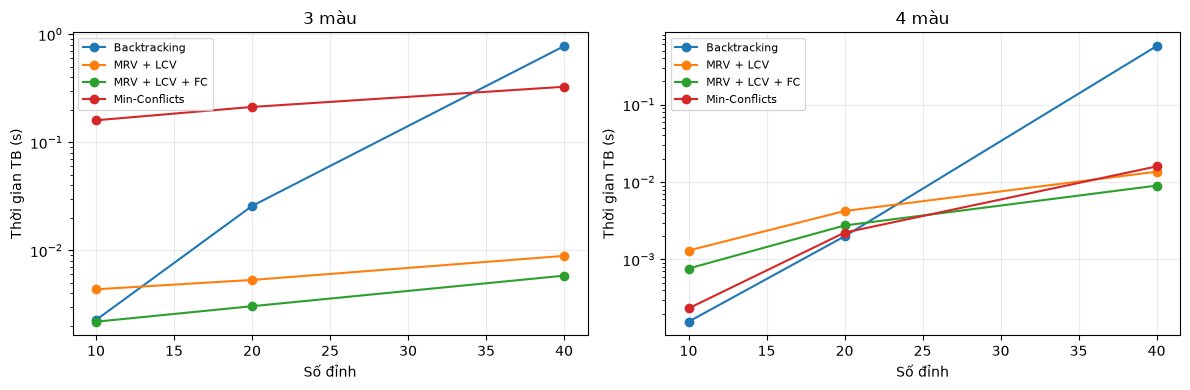

n=10: cạnh TB=21.2; giới hạn đồ thị phẳng 3n−6=24
n=20: cạnh TB=49.1; giới hạn đồ thị phẳng 3n−6=54
n=40: cạnh TB=108.0; giới hạn đồ thị phẳng 3n−6=114


In [12]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for k,ax in zip([3,4],axes):
    for name in [x[0] for x in variants]+['Min-Conflicts']:
        ys=[avg([r for r in graph_records if (r['n'],r['k'],r['algorithm'])==(size,k,name)],'seconds') for size in [10,20,40]]
        ax.plot([10,20,40],ys,'o-',label=name)
    ax.set(xlabel='Số đỉnh',ylabel='Thời gian TB (s)',title=f'{k} màu',yscale='log')
    ax.legend(fontsize=8); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()
for size in [10,20,40]:
    rows=[r for r in graph_records if r['n']==size and r['k']==4 and r['algorithm']=='Backtracking']
    print(f'n={size}: cạnh TB={avg(rows,"edges"):.1f}; giới hạn đồ thị phẳng 3n−6={3*size-6}')

### Nhận xét và trả lời thảo luận 
* Đầy đủ không đồng nghĩa hợp lệ: gán mọi đỉnh cùng màu vẫn `complete=True` nhưng vi phạm cạnh. Nghiệm là phép gán đầy đủ, nằm trong miền và thỏa mọi cạnh.
* MRV giảm phân nhánh bằng chọn biến ít lựa chọn; LCV giữ lựa chọn cho phần còn lại. Forward Checking phát hiện miền rỗng sớm nhưng phải quản lý và khôi phục miền, nên trên đồ thị dễ nó có thể tốn thời gian hơn Backtracking đơn giản. Bảng trên cho phép đối chiếu cả nút lẫn thời gian, không suy ra hiệu quả chỉ từ COUNT.
* Đồ thị phẳng có nghiệm 4 màu nhưng không nhất thiết có nghiệm 3 màu (K4 là ví dụ). Chỉ Backtracking duyệt hết không gian mà không có nghiệm mới chứng minh `unsat`; Min-Conflicts thất bại hay giới hạn nút không đủ kết luận.
* Delaunay tạo đồ thị thưa có số cạnh không vượt 3n−6 khi n≥3, nhưng Backtracking vẫn có độ phức tạp xấu nhất O(k^n), chưa tính chi phí kiểm tra/heuristic. Ba kích thước và 10 seed là khảo sát hữu hạn, chưa đại diện mọi đồ thị phẳng.

### Kết quả quan sát từ lần chạy đã lưu
Với n=40, 4 màu, MRV + LCV + FC đạt 10/10 lượt, COUNT trung bình 73,5 so với Backtracking cơ bản 43.813,5 nút (chỉ đạt 6/10 trong giới hạn). Ở n=10, Backtracking cơ bản nhanh hơn các biến thể heuristic do bài nhỏ và chi phí chọn biến/giá trị. Với 3 màu, MRV + LCV + FC chứng minh vô nghiệm ở 9/10 đồ thị n=10 và toàn bộ đồ thị n=20,40; Backtracking cơ bản n=40 chỉ chứng minh được 4/10, còn 6 lượt hết giới hạn. Min-Conflicts chỉ tìm được 1/10 ở n=10 với 3 màu và 0/10 ở n=20,40; riêng thất bại của tìm kiếm cục bộ không chứng minh vô nghiệm. Cạnh trung bình lần lượt là 21,2; 49,1; 108,0, phù hợp giới hạn 3n−6.

Các số trên mô tả lần chạy đã lưu; khi thay seed phải đọc lại bảng thay vì mặc định tái xuất hiện cùng tỷ lệ. Chuẩn môi trường và phiên bản thư viện được in ở đầu notebook.
